# Lab 06: How to share tools with MCP

## Goal

Move the three Chinook lookups out of the notebook into an MCP server that runs as its own process, call it with the
official MCP client, and then let two hosts use the same server: our own agent loop, and the OpenAI Agents SDK, which
we did not write. The moment that teaches the protocol comes in Part C. We type the request that older tutorials
show, a bare `tools/list`, and the server refuses it. With the two `_meta` keys that MCP's 2026-07-28 revision puts on
every request, the same server answers with its tools, each with an `outputSchema` it wrote from our type hints.

## What you will learn

- what a host, a client, a server and a transport are, and which is which in this lab;
- how to write an MCP server from typed Python functions with `MCPServer` and `@mcp.tool()`, and run it over stdio;
- how to call it with the `mcp` client (`list_tools`, `call_tool`) and read `content`, `structuredContent` and
  `isError`;
- how to read the 2026-07-28 request envelope on the wire (`_meta`, `server/discover`), and what that revision
  removed (the `initialize` handshake) and deprecated (Roots, Sampling, Logging);
- how to let our own agent loop use MCP tools: the tool list turned into Chat Completions schemas, each tool call
  sent to `call_tool`;
- why an MCP server is code you run with your own permissions, and why a stdio server must keep stdout for the
  protocol.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it (lab 00 explains it line by line). This lab adds
`json`, `sqlite3`, `subprocess` and `sys`, all from Python's standard library.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
import subprocess
import sys
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


`EFFORT` is the reasoning effort from `models.env` (`none`): on Chat Completions this model calls function tools only
at `none`. Every Chat Completions call here passes `reasoning_effort=EFFORT or omit`, where `omit` is the `openai`
package's marker for "leave this parameter out", so a model without reasoning (an empty `REASONING_EFFORT`) gets no
`reasoning_effort` at all.

## Hosts, clients, servers and transports

In labs 02 and 03 the lookups were Python functions in this notebook's kernel, the same process as the loop that ran
them. Any other program that wants them (a second notebook, an assistant in your editor, an agent framework) needs its
own copy, and three copies soon become three versions. **MCP**, the Model Context Protocol, is an open standard for
putting tools in a program of their own, a server, that any program speaking the protocol can ask two things: *which
tools do you have?* and *run this one with these arguments*.

MCP does not change who runs a tool. The model still only asks; our code still decides. What changes is where the
tool's code lives and how the program holding the conversation reaches it. Four words name the pieces:

| Term | What it is | In this lab |
|---|---|---|
| **host** | the program that holds the conversation with the model and decides which tool calls to run | our agent loop in this notebook (Part D); the Agents SDK's `Runner` (Part E) |
| **client** | the part of a host that speaks MCP to one server, one connection each | `mcp.Client` (Parts B and D); the SDK's `MCPServerStdio` (Part E) |
| **server** | a program that offers tools (it may also offer resources and prompts; ours offers only tools) | `chinook_server.py`, with the three lookups |
| **transport** | how the messages travel between client and server | **stdio**: the client starts the server as a child process, writes to its stdin and reads its stdout, one JSON message per line |

The picture puts them together:

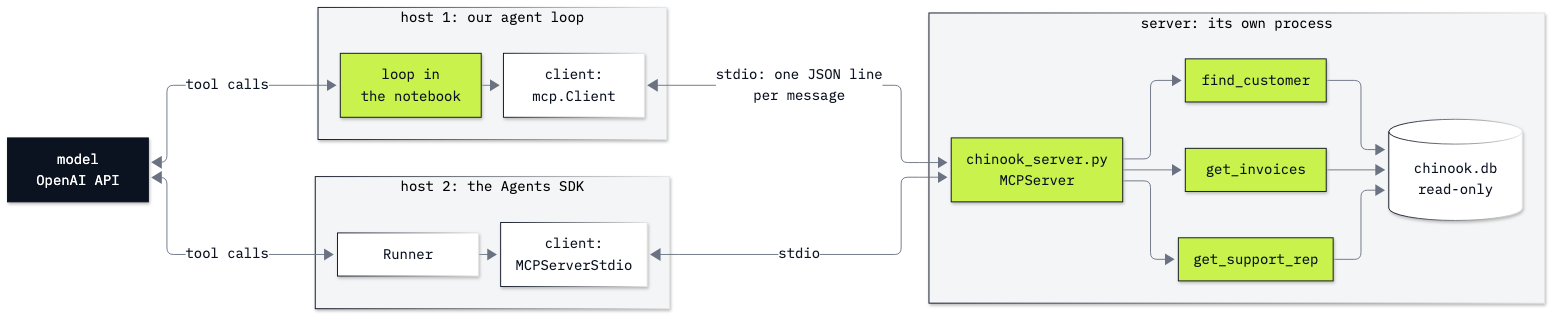

In [2]:
from IPython.display import Image

Image(filename="resources/lab06_mcp_host_client_server.png", width=760)

Read it from left to right:

- the model (ink) only exchanges messages with a host; it never sees the server;
- each host holds its own client, and each client starts its own copy of `chinook_server.py` as a separate process;
- the lime boxes are our code: the loop we write in Part D and the server we write in Part A. The Agents SDK is
  someone else's code, and it reaches our server without a change to either.

Stdio is the transport for a server on the same machine. A server on another machine uses **Streamable HTTP**, the
same JSON messages sent as HTTP requests (see **In production** at the end).

## Part A: Turn the three lookups into an MCP server

This part writes the server: the same three functions as before, in a file that runs as its own process. First the
functions as labs 02 and 03 wrote them, here in the notebook, called by hand, so we know exactly what the server must
return. The database is opened read-only (`mode=ro`), so every write fails whatever arguments arrive.

In [3]:
# The shop database, opened read-only
DB = ROOT / "data" / "chinook.db"
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name):
    """Find customers whose first and last name match `name` exactly."""
    rows = con.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?",
        (name,),
    ).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


print(find_customer("Helena Holý"))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


A list with one dict: a name can match nobody or several people, so the function always returns a list. The other two
take the `customer_id` it returned.

In [4]:
def get_invoices(customer_id):
    """Count a customer's invoices and add up their totals."""
    count, total = con.execute(
        "SELECT COUNT(*), SUM(Total) FROM invoices WHERE CustomerId = ?", (customer_id,)
    ).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": round(total or 0, 2)}


def get_support_rep(customer_id):
    """Name the support rep assigned to a customer."""
    found = con.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?",
        (customer_id,),
    ).fetchone()
    return {"customer_id": customer_id, "support_rep": found[0] if found else None}


print(get_invoices(6))
print(get_support_rep(6))

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


These are the facts every answer in this lab is checked against: **Helena Holý is customer 6, with 7 invoices that add
up to $49.62, and her support rep is Steve Johnson.**

Now the server. It lives in `chinook_server.py`, beside this notebook. Read it top to bottom before we run it:
starting a server means running its code on your machine, with your permissions, so reading a server before you start
it is a habit worth having.

In [5]:
LAB = ROOT / "06_MCP"
SERVER_FILE = LAB / "chinook_server.py"

print(SERVER_FILE.read_text())

"""The three Chinook lookups as an MCP server, run over stdio.

Lab 06 starts this file as its own process; a host can start it the same way:
    python 06_MCP/chinook_server.py
It then reads JSON-RPC messages from stdin and writes its replies to stdout, one per line.
"""

import sqlite3
from pathlib import Path
from typing import TypedDict

from mcp.server import MCPServer

# The repository folder is the first folder above this file that holds data/chinook.db
ROOT = next(p for p in Path(__file__).resolve().parents if (p / "data" / "chinook.db").exists())
DB = ROOT / "data" / "chinook.db"

# Read-only: every write fails, whatever a host asks for
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True, check_same_thread=False)

mcp = MCPServer("chinook")


# The shapes the tools return. MCPServer turns them into each tool's outputSchema.
class Customer(TypedDict):
    customer_id: int
    name: str
    country: str


class Invoices(TypedDict):
    customer_id: int
    invoice_count: int
  

The three function bodies are the ones we just ran. Their docstrings are now the descriptions lab 02 wrote into its
schemas, because here the docstring is what the model reads. What else is new, from the top:

- **The database path comes from the file's own location.** `Path(__file__).resolve().parents` lists the folders
  above the file; the first one that holds `data/chinook.db` is the repository folder. The server then finds the
  database whatever folder it is started from.
- **`mcp = MCPServer("chinook")`** creates the server object. `"chinook"` is the name it reports to clients.
- **`Customer`, `Invoices` and `SupportRep`** are `TypedDict` classes: they describe a dict's keys and the type of
  each value. Python does not check them when the code runs; they are type hints, and `MCPServer` reads them.
- **`@mcp.tool()`** above a function registers it as a tool. The function's name becomes the tool's name, its
  docstring becomes the description (the text the model reads to decide whether to ask for it), and its typed
  parameters become the tool's `inputSchema`. The return type becomes the `outputSchema`. The decorator gives the
  function back unchanged, so it is still a plain Python function.
- **`mcp.run("stdio")`** runs only when the file is started as a program (`if __name__ == "__main__"`). From then on
  the server reads messages from its stdin and writes its replies to its stdout until stdin closes.

In lab 02 we wrote each tool's JSON schema by hand. Here the type hints are the schema: `name: str` and
`customer_id: int` say what the arguments are, and Part B prints what the server wrote from them.

**Checkpoint A.** `find_customer("Helena Holý")` gives customer 6 in the Czech Republic; `get_invoices(6)` gives 7
invoices and 49.62; `get_support_rep(6)` gives Steve Johnson. `chinook_server.py` holds the same three bodies, each
under `@mcp.tool()`, with typed parameters and return types.

## Part B: Call the server with the official MCP client

Part A wrote the server; this part runs it as its own process and talks to it with the `mcp` package's client, with
no model involved. That is how a server is tested: like any program, before a model is allowed to use it.

`StdioServerParameters` says how to start the server: the `command` to run and its `args`. `sys.executable` is the
Python that runs this notebook, so the server gets the same environment, with `mcp` installed. Creating the object
starts nothing.

In [6]:
from mcp import Client, StdioServerParameters

SERVER = StdioServerParameters(command=sys.executable, args=[str(SERVER_FILE)])
print("command: this notebook's Python | args:", [str(Path(a).relative_to(ROOT)) for a in SERVER.args])

command: this notebook's Python | args: ['06_MCP/chinook_server.py']


**The client is asynchronous.** Its methods are coroutines: functions that can pause while they wait for the
server's reply. We call them with `await`. `async with Client(SERVER) as mcp_client:` starts the server process when the block begins
and stops it when the block ends. Lab 07 explains `await`; here it is enough to know that Jupyter runs the event loop
for us, so `await` works directly in a cell (a `.py` script would put this code in an `async def main()` and call
`asyncio.run(main())`).

We ask for the tool list.

In [7]:
async with Client(SERVER) as mcp_client:
    print("protocol version:", mcp_client.protocol_version)
    listed = await mcp_client.list_tools()

print(type(listed).__name__)
print([tool.name for tool in listed.tools])

protocol version: 2026-07-28
ListToolsResult
['find_customer', 'get_invoices', 'get_support_rep']


Three things to read:

- **`protocol version: 2026-07-28`.** Before anything else, the client asked the server which protocol versions it
  speaks and chose the newest they share. Part C sends that question by hand.
- **`ListToolsResult`** is an object of the `mcp` package, and `listed.tools` is a list of `Tool` objects, one per
  function we decorated, in the order the file defines them.
- **The process has already stopped.** The block ended, so the server exited; `listed` is an ordinary object in
  memory.

One tool in full, field by field:

In [8]:
tool = listed.tools[0]

print("name:       ", tool.name)
print("description:", tool.description)
print("inputSchema:", json.dumps(tool.input_schema, indent=2, ensure_ascii=False))

name:        find_customer
description: Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.
inputSchema: {
  "type": "object",
  "properties": {
    "name": {
      "title": "Name",
      "type": "string"
    }
  },
  "required": [
    "name"
  ],
  "title": "find_customerArguments"
}


The name and the description came from the function and its docstring. The `inputSchema` is the JSON Schema the
server wrote from `name: str`: an object with one string property, `name`, which is required. It is the same shape as
lab 02's hand-written schema for `find_customer`. The `title` keys are labels the schema generator adds; nothing reads
them.

**Python names and wire names.** In Python the field is `tool.input_schema`; in the JSON message (Part C) it is
`inputSchema`. The `mcp` package converts between the two spellings, so the Python attributes are snake case and the
protocol's fields are camel case.

Now the output side: what each tool promises to return.

In [9]:
print(json.dumps(tool.output_schema, indent=2))

{
  "$defs": {
    "Customer": {
      "properties": {
        "customer_id": {
          "title": "Customer Id",
          "type": "integer"
        },
        "name": {
          "title": "Name",
          "type": "string"
        },
        "country": {
          "title": "Country",
          "type": "string"
        }
      },
      "required": [
        "customer_id",
        "name",
        "country"
      ],
      "title": "Customer",
      "type": "object"
    }
  },
  "properties": {
    "result": {
      "items": {
        "$ref": "#/$defs/Customer"
      },
      "title": "Result",
      "type": "array"
    }
  },
  "required": [
    "result"
  ],
  "title": "find_customerOutput",
  "type": "object"
}


`find_customer` returns a list, and an MCP tool's structured result must be a JSON object, so the server wraps the
list in an object with one key, `result`: an array whose items follow the `Customer` shape. `$defs` holds the shape
once, and `"$ref": "#/$defs/Customer"` points to it. The other two tools return a `TypedDict`, which is already an
object, so their schemas are the shapes themselves:

In [10]:
for tool in listed.tools[1:]:
    print(tool.name, "->", tool.output_schema["properties"])

get_invoices -> {'customer_id': {'title': 'Customer Id', 'type': 'integer'}, 'invoice_count': {'title': 'Invoice Count', 'type': 'integer'}, 'total': {'title': 'Total', 'type': 'number'}}
get_support_rep -> {'customer_id': {'title': 'Customer Id', 'type': 'integer'}, 'support_rep': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'title': 'Support Rep'}}


`get_invoices` promises `customer_id` (integer), `invoice_count` (integer) and `total` (number); `get_support_rep`
promises `customer_id` and `support_rep`, a string or `null` (the `str | None` in the type hint).

Now one call. `call_tool` takes the tool's name and a Python dict of arguments; the client turns the dict into JSON.

In [11]:
async with Client(SERVER) as mcp_client:
    result = await mcp_client.call_tool("find_customer", {"name": "Helena Holý"})

print(type(result).__name__)
print("content:          ", result.content)
print("structuredContent:", result.structured_content)
print("isError:          ", result.is_error)

CallToolResult
content:           [TextContent(type='text', text='{\n  "customer_id": 6,\n  "name": "Helena Holý",\n  "country": "Czech Republic"\n}', annotations=None, meta=None)]
structuredContent: {'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}
isError:           False


A `CallToolResult` with three fields to know:

| Field | What it holds here | Who it is for |
|---|---|---|
| `content` | a list of content blocks; here one `TextContent` whose `text` is the result written as JSON | the model: a host sends this text back as the tool result |
| `structuredContent` | `{'result': [{'customer_id': 6, ...}]}`, the same data as a JSON object that follows the `outputSchema` | code: a host can read fields without parsing text |
| `isError` | `False`: the tool ran and returned | the host, and through it the model |

The values are the ones `find_customer` gave in Part A, but this time they came from another process.

Why is `content` a list? A tool that returns a list sends one text block per item, so one match gave one block. A name
that matches nobody shows the other end: Helena's name typed without its accent.

In [12]:
async with Client(SERVER) as mcp_client:
    nobody = await mcp_client.call_tool("find_customer", {"name": "Helena Holy"})

print("content:          ", nobody.content)
print("structuredContent:", nobody.structured_content)
print("isError:          ", nobody.is_error)

content:           []
structuredContent: {'result': []}
isError:           False


No match: `content` is an empty list, `structuredContent` is `{'result': []}`, and `isError` is `False`, because
finding nobody is a correct answer, not a failure. A host that sends the model only `content[0]` would crash here, and
would drop matches when there are several; Part D's loop joins every text block instead.

What does a failure look like? We send `"six"` where the schema says `customer_id` is an integer.

In [13]:
async with Client(SERVER) as mcp_client:
    bad = await mcp_client.call_tool("get_invoices", {"customer_id": "six"})

print("isError:", bad.is_error)
print("structuredContent:", bad.structured_content)
print(bad.content[0].text)

isError: True
structuredContent: None
Error executing tool get_invoices: 1 validation error for get_invoicesArguments
customer_id
  Input should be a valid integer, unable to parse string as an integer [type=int_parsing, input_value='six', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/int_parsing


The server checked the arguments against the `inputSchema` before running anything, and refused them. The failure is
not an exception in our code: it comes back as an ordinary result with `isError` `True`, no structured content, and a
text that says what was wrong (`Input should be a valid integer`). A host sends that text to the model like any other
result, so the model can read it and try again, the way lab 03 returned errors as observations.

Each `async with` above started a fresh server process and stopped it at the end of the block. One process per block
is fine for trying a server out; a host keeps one connection open for a whole conversation, as Part D's loop does.

**Checkpoint B.** Protocol version `2026-07-28`; three tools, `find_customer`, `get_invoices` and `get_support_rep`;
`find_customer`'s `structuredContent` is `{'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech
Republic'}]}`; `"Helena Holy"` without the accent gives an empty `content` and `{'result': []}`; `get_invoices` with
`"six"` gives `isError: True` and `Input should be a valid integer`.

## Part C: Read the request envelope on the wire

The client hid the messages. In this part we start the same server ourselves and write each message by hand, to see
exactly what the 2026-07-28 revision asks of a request, and why the bare request older tutorials show is refused.

**JSON-RPC in one paragraph.** Every MCP message is a JSON-RPC 2.0 message. A request is an object with `jsonrpc`
(always `"2.0"`), an `id` we choose, a `method` (the procedure to run, such as `tools/list`) and `params`. The answer
carries the same `id` and either a `result` or an `error` with a numeric `code` and a `message`. On stdio each message
is one line of JSON: `json.dumps` writes a dict on one line by default, and `"\n"` ends it.

**The envelope.** Since 2026-07-28 there is no opening handshake. Instead every request carries two keys in
`params._meta`: the protocol version it speaks, and the client's capabilities, the things the client can do for the
server. Ours offers none, so its capabilities are an empty object.

In [14]:
META = {
    "io.modelcontextprotocol/protocolVersion": "2026-07-28",
    "io.modelcontextprotocol/clientCapabilities": {},
}

`subprocess.Popen` starts the server the way the client did, as a child process. `stdin=subprocess.PIPE` and
`stdout=subprocess.PIPE` give us its two standard streams as files we can write to and read from; `stderr` is a third
pipe, kept apart (Part F reads it). `text=True` with `encoding="utf-8"` lets us write and read strings instead of
bytes, which matters for the `ý` in Helena's name.

In [15]:
process = subprocess.Popen(
    [sys.executable, str(SERVER_FILE)],
    stdin=subprocess.PIPE,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    encoding="utf-8",
)
print("server running:", process.poll() is None)

server running: True


`process.poll()` returns `None` while the process is alive. The server is now waiting on its stdin.

The first request asks the question the client asked in Part B: `server/discover`, which versions and features does
the server support? We write one line, `flush()` pushes it through the pipe at once, and `readline()` waits for one
line back.

In [16]:
request = {"jsonrpc": "2.0", "id": 1, "method": "server/discover", "params": {"_meta": META}}

process.stdin.write(json.dumps(request) + "\n")
process.stdin.flush()
line = process.stdout.readline()
print(line)

{"jsonrpc":"2.0","id":1,"result":{"cacheScope":"private","capabilities":{"prompts":{"listChanged":true},"resources":{"listChanged":true,"subscribe":true},"tools":{"listChanged":true}},"resultType":"complete","supportedVersions":["2026-07-28"],"ttlMs":0,"_meta":{"io.modelcontextprotocol/serverInfo":{"name":"chinook","version":""}}}}



One line of JSON came back, with our `id` 1. The same three steps (write a line, flush, read a line) are every
exchange in this part, so we put them in a function, `send`, that also parses the reply with `json.loads`, and send
the same request again to read it laid out:

In [17]:
def send(process, message):
    """Write one JSON-RPC message as a line, read one line back and parse it."""
    process.stdin.write(json.dumps(message) + "\n")
    process.stdin.flush()
    return json.loads(process.stdout.readline())


print(json.dumps(send(process, request), indent=2))

{
  "jsonrpc": "2.0",
  "id": 1,
  "result": {
    "cacheScope": "private",
    "capabilities": {
      "prompts": {
        "listChanged": true
      },
      "resources": {
        "listChanged": true,
        "subscribe": true
      },
      "tools": {
        "listChanged": true
      }
    },
    "resultType": "complete",
    "supportedVersions": [
      "2026-07-28"
    ],
    "ttlMs": 0,
    "_meta": {
      "io.modelcontextprotocol/serverInfo": {
        "name": "chinook",
        "version": ""
      }
    }
  }
}


The `result` of `server/discover`, key by key:

- **`supportedVersions`**: `["2026-07-28"]`, the versions this server speaks with the per-request envelope;
- **`capabilities`**: the kinds of things it offers (`tools`, `prompts`, `resources`), as the SDK sets them up;
- **`resultType`**: `"complete"`. Every result in this revision says whether it is final, so a server could instead
  ask the client for more input;
- **`_meta`**: `io.modelcontextprotocol/serverInfo`, the server's name (`chinook`), stamped on every result;
- **`cacheScope`** and **`ttlMs`**: hints that tell a client whether and for how long it may cache the answer.

Now `tools/list`, with the envelope:

In [18]:
reply = send(process, {"jsonrpc": "2.0", "id": 2, "method": "tools/list", "params": {"_meta": META}})

print("keys of result:", list(reply["result"]))
print("tools:", [tool["name"] for tool in reply["result"]["tools"]])
print(json.dumps(reply["result"]["tools"][1], indent=2))

keys of result: ['cacheScope', 'resultType', 'tools', 'ttlMs', '_meta']
tools: ['find_customer', 'get_invoices', 'get_support_rep']
{
  "description": "Count a customer's invoices and add up their total in US dollars.",
  "inputSchema": {
    "type": "object",
    "properties": {
      "customer_id": {
        "title": "Customer Id",
        "type": "integer"
      }
    },
    "required": [
      "customer_id"
    ],
    "title": "get_invoicesArguments"
  },
  "name": "get_invoices",
  "outputSchema": {
    "properties": {
      "customer_id": {
        "title": "Customer Id",
        "type": "integer"
      },
      "invoice_count": {
        "title": "Invoice Count",
        "type": "integer"
      },
      "total": {
        "title": "Total",
        "type": "number"
      }
    },
    "required": [
      "customer_id",
      "invoice_count",
      "total"
    ],
    "title": "Invoices",
    "type": "object"
  }
}


Accepted. The same three tools as in Part B, now as raw JSON: `inputSchema` and `outputSchema` in camel case, exactly
what `mcp_client.list_tools()` read for us. The `outputSchema` of `get_invoices` is the `Invoices` shape from our type
hints.

**Predict:** older tutorials, written for the protocol before 2026-07-28, send `tools/list` with empty `params`. Will
this server answer it?

In [19]:
bare = {"jsonrpc": "2.0", "id": 3, "method": "tools/list", "params": {}}

print(json.dumps(send(process, bare), indent=2))

{
  "jsonrpc": "2.0",
  "id": 3,
  "error": {
    "code": -32602,
    "message": "params._meta must be an object carrying the required 'io.modelcontextprotocol/protocolVersion' and 'io.modelcontextprotocol/clientCapabilities' envelope keys"
  }
}


Refused, with an `error` instead of a `result`:

- **`code` -32602** is JSON-RPC's "invalid params": the method exists, but the parameters are wrong;
- **`message`** names what is missing: `params._meta` must carry the two envelope keys,
  `io.modelcontextprotocol/protocolVersion` and `io.modelcontextprotocol/clientCapabilities`.

The request is a valid JSON-RPC message, and the method is real. What it lacks is the envelope: since 2026-07-28 each
request must say for itself which version of the protocol it speaks, and what came earlier on the connection does not
count.

We stop this server by closing its stdin, which is how a stdio client ends a server: it reads the end of its input and
exits. `wait()` waits for that and returns the exit code.

In [20]:
process.stdin.close()
print("exit code:", process.wait())

exit code: 0


Exit code 0: a clean stop.

**What if the bare request comes first?** We start a fresh process and send the bare `tools/list` as its very first
message, then the enveloped one. We start servers three more times in this lab, so the `Popen` call goes in a small
function with the same arguments as above.

In [21]:
def start_server(path):
    """Start an MCP server file as a child process with its three standard streams as text pipes."""
    return subprocess.Popen(
        [sys.executable, str(path)],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
        encoding="utf-8",
    )


process = start_server(SERVER_FILE)
print(send(process, bare))
print(send(process, {"jsonrpc": "2.0", "id": 4, "method": "tools/list", "params": {"_meta": META}}))

{'jsonrpc': '2.0', 'id': 3, 'error': {'code': -32602, 'message': 'Invalid request parameters', 'data': ''}}
{'jsonrpc': '2.0', 'id': 4, 'error': {'code': -32600, 'message': 'this connection serves the handshake protocol era; requests carrying the 2026-07-28 envelope are not accepted on it'}}


Two different errors this time:

1. The bare `tools/list` gets -32602 with only `Invalid request parameters`: no word about the envelope.
2. The enveloped request, which the first process answered, is now refused with -32600 ("invalid request"): *this
   connection serves the handshake protocol era; requests carrying the 2026-07-28 envelope are not accepted on it*.

**The first request decides which protocol a connection speaks, once.** A request with the envelope opens a
2026-07-28 connection. Anything else is taken as an older client of the **handshake era**, the protocol before
2026-07-28, in which a connection had to open with an `initialize` request; a `tools/list` before that is invalid,
which is the first error. This server still speaks the old protocol to old clients (the specification allows a server
to support both), but one connection speaks one era. We can finish the old handshake on this connection to see it:

In [22]:
handshake = {
    "jsonrpc": "2.0",
    "id": 5,
    "method": "initialize",
    "params": {"protocolVersion": "2025-11-25", "capabilities": {}, "clientInfo": {"name": "lab06", "version": "1"}},
}
print(send(process, handshake))

process.stdin.close()
print("exit code:", process.wait())

{'jsonrpc': '2.0', 'id': 5, 'result': {'capabilities': {'prompts': {'listChanged': False}, 'resources': {'listChanged': False, 'subscribe': False}, 'tools': {'listChanged': False}}, 'protocolVersion': '2025-11-25', 'serverInfo': {'name': 'chinook', 'version': ''}}}
exit code: 0


The server answers the `initialize` with `protocolVersion` `2025-11-25`, the last revision with a handshake, and its
capabilities. An old client would go on from there; new clients do not need this step.

**What the 2026-07-28 revision changed** (from the specification's changelog), on the points this lab meets:

| Change | What it means here |
|---|---|
| **Removed** the `initialize` / `notifications/initialized` handshake | every request carries its protocol version and client capabilities in `_meta` (our `META`) |
| **Added** `server/discover` | the question the client asked first in Part B, which we sent by hand |
| **Removed** protocol-level sessions on Streamable HTTP (the `Mcp-Session-Id` header) | a server keeps no per-connection state; each request stands alone |
| **Added** `resultType` on every result | `"complete"` on every reply we read |
| **Removed** `ping` and `logging/setLevel` | a client opts into log messages per request instead |
| **Deprecated** Roots, Sampling and Logging | they still work for now, but new servers and clients should not adopt them: pass folders as tool parameters, call a model provider directly, and log to stderr (Part F) or OpenTelemetry |

One thing has not changed: on stdio a message is one line of JSON and nothing else. Some older material shows MCP
messages behind a `Content-Length:` header; that framing belongs to another protocol (the Language Server Protocol),
and MCP's stdio transport never used it.

**Checkpoint C.** `server/discover` gives `supportedVersions` `["2026-07-28"]`; `tools/list` with `_meta` gives the
three tools; on the same connection the bare `tools/list` gives -32602 naming the two envelope keys. On a fresh
connection the bare request first gives -32602 `Invalid request parameters`, the enveloped one after it -32600
(handshake era), and `initialize` is answered with `2025-11-25`.

## Part D: Use the server's tools from our own agent loop

We have a server and know what its messages look like. This part makes our own agent loop a host: the loop lab 03
wrote, with one change. Instead of looking a tool's name up in a dict of Python functions, it sends each tool call to
the server with `call_tool`.

To be sure the answer comes from the server, we first remove our own copies: we close the notebook's database
connection and delete the three functions from Part A.

In [23]:
con.close()
del find_customer, get_invoices, get_support_rep

print("lookups left in this notebook:", [n for n in ("find_customer", "get_invoices", "get_support_rep") if n in globals()])

lookups left in this notebook: []


`globals()` is the dict of names defined in this notebook; none of the three is left, and the database connection is
closed. From here on, nothing in this kernel can run the SQL.

The model reads tools in the Chat Completions format from lab 02: `{"type": "function", "function": {name,
description, parameters}}`. An MCP `Tool` already has all three, so turning one into the other is a small function:

In [24]:
def to_chat_tool(tool):
    """Turn one MCP tool into the tool dict Chat Completions expects."""
    return {
        "type": "function",
        "function": {"name": tool.name, "description": tool.description, "parameters": tool.input_schema},
    }


print(json.dumps(to_chat_tool(listed.tools[0]), indent=2, ensure_ascii=False))

{
  "type": "function",
  "function": {
    "name": "find_customer",
    "description": "Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.",
    "parameters": {
      "type": "object",
      "properties": {
        "name": {
          "title": "Name",
          "type": "string"
        }
      },
      "required": [
        "name"
      ],
      "title": "find_customerArguments"
    }
  }
}


The same name and description as lab 02's `FIND_CUSTOMER_TOOL`, and the server's `inputSchema` as `parameters`. One
difference: no `"strict": true`. Strict mode needs `additionalProperties: false` on every object in the schema, and
the server's schema does not say it, so we send the schema without strict mode and the API treats it as guidance. (A
host could add the key before sending; the simplest version leaves it out.)

Now the model client and the call we have used since lab 02, with the settings in one place:

In [25]:
from openai import OpenAI, omit

client = OpenAI()

SYSTEM = "You are a support assistant for the Chinook music shop."
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"


def ask_model(messages, tools):
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=tools,
        reasoning_effort=EFFORT or omit,
        max_completion_tokens=300,
    )
    return response.choices[0].message

The loop, step by step:

1. start the server, ask it for its tools and turn each into a Chat Completions tool;
2. send the conversation and the tools to the model;
3. if the reply has no tool calls, it is the answer: return it;
4. otherwise append the reply, and for each tool call parse its arguments, send them to the server with `call_tool`,
   and append the result's text as a tool message with the call's id. The text is every text block in `content` (the
   part meant for the model), joined with newlines, so a result with several items or none still reaches the model
   whole;
5. go back to step 2, at most `max_turns` times.

Only step 4 differs from lab 03: `await mcp_client.call_tool(name, args)` instead of `FUNCTIONS[name](**args)`.
Because `call_tool` must be awaited, the function that contains it is written `async def`, and we `await` it in turn.
It returns the answer, the number of model calls, and every tool call it sent with the `structuredContent` that came
back.

In [26]:
async def run_agent(question, max_turns=5):
    async with Client(SERVER) as mcp_client:
        listed = await mcp_client.list_tools()
        tools = [to_chat_tool(tool) for tool in listed.tools]
        messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
        calls = []
        for turn in range(1, max_turns + 1):
            reply = ask_model(messages, tools)
            if not reply.tool_calls:
                return reply.content, turn, calls
            messages.append(reply)
            for call in reply.tool_calls:
                args = json.loads(call.function.arguments)
                result = await mcp_client.call_tool(call.function.name, args)
                calls.append((turn, call.function.name, args, result.structured_content))
                # Every text block, joined: a list result comes as one block per item
                text = "\n".join(block.text for block in result.content if block.type == "text")
                messages.append({"role": "tool", "tool_call_id": call.id, "content": text})
    return None, max_turns, calls

The Helena question, through the server:

In [27]:
answer, model_calls, calls = await run_agent(QUESTION)

for turn, name, args, structured in calls:
    print(f"turn {turn}: {name}({args}) -> {structured}")
print("\nmodel calls:", model_calls)
print(answer)

turn 1: find_customer({'name': 'Helena Holý'}) -> {'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}
turn 2: get_invoices({'customer_id': 6}) -> {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
turn 2: get_support_rep({'customer_id': 6}) -> {'customer_id': 6, 'support_rep': 'Steve Johnson'}

model calls: 3
Helena Holý has **7 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


Three model calls, and every lookup went through the server:

- **turn 1:** only `find_customer`. The other two tools need a `customer_id`, and the model did not have one yet;
- **turn 2:** `get_invoices` and `get_support_rep` in one reply, both with `customer_id` 6 from the first result. Our
  loop sent each to the server with `call_tool`, one after the other;
- **turn 3:** no tool calls, so the reply is the answer: 7 invoices, $49.62, Steve Johnson.

The `structuredContent` printed beside each call is what the server process sent back; the model read the same values
as the text of `content`.

A check in code that the three facts reached the reply:

In [28]:
for fact in ["7", "49.62", "Steve Johnson"]:
    print("✅" if fact in answer else "❌", fact)

✅ 7
✅ 49.62
✅ Steve Johnson


All three facts are in the reply. The check reads strings, not meaning (a reply saying "49.62 invoices" would pass),
so read the reply as well. What it does establish, with the lookups deleted from this notebook, is that the values came from the server
process.

**Checkpoint D.** Our copies of the lookups are gone; the loop calls `find_customer`, then `get_invoices` and
`get_support_rep`, all through `call_tool`; the answer says 7 invoices, $49.62 and Steve Johnson.

## Part E: Use the same server from a host we did not write

Our loop works with our server, but we wrote both ends, so it proves little about the protocol. The reason to have a
protocol is that a host we did not write can use our tools. This part uses the OpenAI Agents SDK as that host (lab 07
teaches the SDK itself); the server file does not change.

`MCPServerStdio` is the SDK's MCP client for a stdio server. Its `params` are the same two things as
`StdioServerParameters`: the command and its arguments. `async with` connects it (and starts the server), as with
`Client`.

The SDK also uploads a trace of every run to the OpenAI dashboard by default; lab 07 reads traces, so we switch that
off here with `set_tracing_disabled(True)`.

In [29]:
from agents import Agent, ModelSettings, Runner, set_tracing_disabled
from agents.mcp import MCPServerStdio
from openai.types.shared import Reasoning

set_tracing_disabled(True)

sdk_server = MCPServerStdio(name="chinook", params={"command": sys.executable, "args": [str(SERVER_FILE)]})

async with sdk_server:
    sdk_tools = await sdk_server.list_tools()

print(type(sdk_tools[0]).__module__, type(sdk_tools[0]).__name__)
print([tool.name for tool in sdk_tools])

mcp_types._types Tool
['find_customer', 'get_invoices', 'get_support_rep']


The SDK got the same three tools, as the same `Tool` objects: `MCPServerStdio` is the SDK's own class, but underneath
it uses the `mcp` package from Part B.

Now an `Agent` that uses the server. `mcp_servers=[sdk_server]` is the only line that connects it to our tools; the
SDK lists them, turns them into model tools and sends each call back to the server, the work our `run_agent` does by
hand. `model_settings` passes the reasoning effort from `models.env`: the SDK fills in its own effort only for model
names that start with `gpt-5`, so we set it ourselves. With an empty `REASONING_EFFORT`, `EFFORT` is `None` and the SDK
sends `"reasoning": {"effort": null}`, which the Responses API the SDK uses accepts.

In [30]:
agent = Agent(
    name="Chinook desk",
    instructions=SYSTEM,
    model=MODEL,
    mcp_servers=[sdk_server],
    model_settings=ModelSettings(reasoning=Reasoning(effort=EFFORT)),
)

async with sdk_server:
    sdk_result = await Runner.run(agent, QUESTION)

print(sdk_result.final_output)

Helena Holý has **7 invoices** totaling **$49.62**. Her support rep is **Steve Johnson**.


The same facts as our loop's answer: 7 invoices, $49.62 and Steve Johnson. What did the SDK send to our server?
`sdk_result.new_items` lists what happened during the run, in order: each tool call the model asked for, each result,
and the final message.

In [31]:
for item in sdk_result.new_items:
    if item.type == "tool_call_item":
        print("tool call:  ", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("tool result:", item.output["text"].replace("\n", " "))
print("model calls:", sdk_result.context_wrapper.usage.requests)

tool call:   find_customer {"name":"Helena Holý"}
tool result: {   "customer_id": 6,   "name": "Helena Holý",   "country": "Czech Republic" }
tool call:   get_invoices {"customer_id":6}
tool call:   get_support_rep {"customer_id":6}
tool result: {   "customer_id": 6,   "invoice_count": 7,   "total": 49.62 }
tool result: {   "customer_id": 6,   "support_rep": "Steve Johnson" }
model calls: 3


Three model calls and the same plan as our loop: `find_customer` first, then `get_invoices` and `get_support_rep`
in one reply (both calls are listed before their two results). Each tool result is the `content` text our server sent
back. The SDK did with `list_tools` and `call_tool` what our loop does, and we changed nothing in the server for it.

**The same server, two hosts.** Neither host knows how the lookups work, and the server does not know which host is
calling. The model chooses its calls on every run, so one run of each proves little; we run each host three more times
and count.

In [32]:
for host in ["our loop", "Agents SDK"]:
    for run in range(1, 4):
        if host == "our loop":
            text, model_calls, calls = await run_agent(QUESTION)
            tools_called = [name for turn, name, args, structured in calls]
        else:
            async with sdk_server:
                result = await Runner.run(agent, QUESTION)
            text, model_calls = result.final_output, result.context_wrapper.usage.requests
            tools_called = [item.raw_item.name for item in result.new_items if item.type == "tool_call_item"]
        facts = all(fact in text for fact in ["7", "49.62", "Steve Johnson"])
        print(f"{host:10} run {run} | model calls {model_calls} | {tools_called} | {'✅' if facts else '❌'} facts")

our loop   run 1 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


our loop   run 2 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


our loop   run 3 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


Agents SDK run 1 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


Agents SDK run 2 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


Agents SDK run 3 | model calls 3 | ['find_customer', 'get_invoices', 'get_support_rep'] | ✅ facts


All six runs made three model calls, called the same three tools on our server, and gave the three facts. The model
chooses its calls on every run, so six runs do not prove it never varies; they show the two hosts doing the same work
through the same server.

**Checkpoint E.** The SDK lists the same three tools; its answer says 7 invoices, $49.62 and Steve Johnson after
calling `find_customer`, `get_invoices` and `get_support_rep` on our server; over the repeated runs, 3 model calls
and the three facts in every run (3 of 3 for each host here).

## Part F: Keep stdout for the protocol

On stdio, the server's stdout *is* the protocol channel: every line the client reads there must be a JSON-RPC
message. A habit that is harmless in a notebook, a `print()` to see what a function is doing, writes to that channel.
This part adds one print to `get_invoices` and follows the text to see where it lands.

We make a copy of the server with one line added after the docstring of `get_invoices`, and save it in `outputs/`
beside this notebook (a folder git ignores). The copy finds the database the same way, by walking up from its own
location.

In [33]:
original = SERVER_FILE.read_text()
docstring = '    """Count a customer\'s invoices and add up their total in US dollars."""\n'

PRINTING_FILE = LAB / "outputs" / "chinook_server_print.py"
PRINTING_FILE.parent.mkdir(exist_ok=True)
PRINTING_FILE.write_text(original.replace(docstring, docstring + '    print(f"looking up {customer_id}")\n'))

print([line for line in PRINTING_FILE.read_text().splitlines() if "looking up" in line])

['    print(f"looking up {customer_id}")']


First on the raw wire, with Part C's `send`: one `tools/call` for customer 6. A `tools/call` request names the tool
and its arguments in `params`, beside the envelope. After the reply we stop the server and read whatever else it
wrote to stdout and stderr.

In [34]:
call = {
    "jsonrpc": "2.0",
    "id": 1,
    "method": "tools/call",
    "params": {"name": "get_invoices", "arguments": {"customer_id": 6}, "_meta": META},
}

process = start_server(PRINTING_FILE)
reply = send(process, call)
process.stdin.close()
process.wait()

print("reply:          ", reply["result"]["structuredContent"])
print("stdout, after it:", repr(process.stdout.read()))
print("stderr:          ", repr(process.stderr.read()))

reply:           {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
stdout, after it: 'looking up 6\n'
stderr:           ''


The reply is right, and then, after the server stopped, its stdout carried one more line: `looking up 6`. That line
is not a JSON-RPC message.

**Why did it come after the reply, not before?** Two details we did not choose:

1. `print` writes into a buffer inside the Python process and sends it on later; with stdout connected to a pipe,
   Python sends it when the buffer fills or the program ends.
2. While it serves, `mcp`'s stdio server points the process's stdout at stderr and writes its own replies through a
   private copy of the pipe, so stray output misses the wire. When it stops, it gives stdout back, and the buffered
   `looking up 6` was written then, onto the protocol channel.

Now the same server through the official client. The client reports a line it cannot parse in its log, through
Python's `logging` module, under the logger name `mcp.client.stdio`. `BufferingHandler`, from the standard library,
keeps every log record it receives in a list, `.buffer`, so we can read the client's log here (without a handler,
Python would print the record with a long traceback).

In [35]:
import logging
from logging.handlers import BufferingHandler

client_log = BufferingHandler(capacity=100)
logging.getLogger("mcp.client.stdio").addHandler(client_log)

async with Client(StdioServerParameters(command=sys.executable, args=[str(PRINTING_FILE)])) as mcp_client:
    result = await mcp_client.call_tool("get_invoices", {"customer_id": 6})

print("result:", result.structured_content)
print("client log records:", len(client_log.buffer))
for record in client_log.buffer:
    print(record.levelname, record.name, "|", record.getMessage())
    print(record.exc_info[1])

result: {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
client log records: 1
ERROR mcp.client.stdio | Failed to parse JSONRPC message from server
1 validation error for union[JSONRPCRequest,JSONRPCNotification,JSONRPCResponse,JSONRPCError]
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='looking up 6', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/json_invalid


The result arrived, and when the server stopped, the client logged an `ERROR`: *Failed to parse JSONRPC message from
server*. The error it
attached says why: `Invalid JSON: expected value at line 1 column 1`, with `input_value='looking up 6'`, our printed
text, read where a message should be.

So the answer was right and the stream was not clean. The answer survived because of the two details above, the
buffer and the `mcp` package's guard on stdout, and neither is a promise of the protocol. The specification says a stdio server **must
not** write anything to its stdout that is not a valid MCP message, and that it **may** write to stderr for logging,
which the client may capture, forward or ignore.

**The fix: write diagnostics to stderr.** `print(..., file=sys.stderr)` sends the text to stderr instead; the
`logging` module writes to stderr by default too (that is where `MCPServer`'s own messages go, such as the refused
`"six"` in Part B). We make a second copy with that print, and with `import sys`, which the print needs.

In [36]:
STDERR_FILE = LAB / "outputs" / "chinook_server_stderr.py"
fixed = original.replace("import sqlite3\n", "import sqlite3\nimport sys\n", 1)
fixed = fixed.replace(docstring, docstring + '    print(f"looking up {customer_id}", file=sys.stderr)\n')
STDERR_FILE.write_text(fixed)

process = start_server(STDERR_FILE)
reply = send(process, call)
process.stdin.close()
process.wait()

print("reply:          ", reply["result"]["structuredContent"])
print("stdout, after it:", repr(process.stdout.read()))
print("stderr:          ", repr(process.stderr.read()))

reply:           {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
stdout, after it: ''
stderr:           'looking up 6\n'


The same reply, nothing more on stdout, and `looking up 6` on stderr, where a diagnostic belongs. And through the
client, with its log emptied first:

In [37]:
client_log.buffer.clear()

async with Client(StdioServerParameters(command=sys.executable, args=[str(STDERR_FILE)])) as mcp_client:
    result = await mcp_client.call_tool("get_invoices", {"customer_id": 6})

print("result:", result.structured_content)
print("client log records:", len(client_log.buffer))

result: {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
client log records: 0


The result, and no log record: the client read nothing it could not parse.

**Where does the server's stderr go?** When `Client` starts a server, it passes the server's stderr on to the stderr of
the program that started it. In a notebook that text usually lands in the terminal or log where Jupyter runs, not in
the cell, which is why the `"six"` refusal in Part B left no message here.

**Checkpoint F.** With `print()`: the reply is right, `'looking up 6\n'` follows on stdout after the server stops, and
the client logs one `ERROR` whose error reads `Invalid JSON ... input_value='looking up 6'`. With
`print(..., file=sys.stderr)`: stdout holds nothing more, stderr holds `'looking up 6\n'`, and the client logs nothing.

## In production

- **Streamable HTTP** is the transport for a server on another machine: each request is an HTTP POST to one
  endpoint, and since 2026-07-28 there is no session to keep (the `Mcp-Session-Id` header is gone). The same file
  runs that way with `mcp.run("streamable-http")`, and `Client("http://host:port/mcp")` takes a URL instead of
  `StdioServerParameters`. A remote server needs what any web service needs: authentication (MCP specifies OAuth for
  it), and care about what data you send it.
- **Registries** list servers to install: the official MCP Registry, and the lists inside editors and desktop
  assistants. A stdio server from a list is a program that runs with your permissions; a remote one sees what you
  send. Read it, pin its version, and give it read-only access where you can, as `chinook_server.py` does.
- **Tool descriptions are text the model reads.** A server can put instructions in a tool's description or in a tool
  result as easily as data (**tool poisoning**), and the model may follow them. Lab 19 shows untrusted text steering
  an agent, and the defences.

## What you can do now

- Name the host, client, server and transport in an MCP setup, and say which one runs the tool (Part A and the
  diagram).
- Write an MCP server from typed functions with `MCPServer` and `@mcp.tool()`, and say where each part of a tool's
  schema comes from (Part A, Part B).
- Call a server with `mcp.Client` over stdio and read `content`, `structuredContent` and `isError`, including a call
  the server refuses (Part B).
- Write a 2026-07-28 request by hand, with its `_meta` envelope, and explain the -32602 and -32600 errors a bare
  request gets (Part C).
- Make your own agent loop an MCP host: tools from `list_tools`, calls through `call_tool` (Part D).
- Give the same server to the Agents SDK with `MCPServerStdio` and compare the two hosts' runs (Part E).
- Keep a stdio server's stdout for the protocol, and send diagnostics to stderr (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `-32602` "params._meta must be an object carrying the required ... envelope keys" | a request without the 2026-07-28 envelope | add `"_meta": META` to `params` |
| `-32600` "this connection serves the handshake protocol era" | the connection's first request had no envelope | start a fresh server process and send the enveloped request first |
| `isError: True` and `Input should be a valid integer` | arguments that do not match the tool's `inputSchema` | send the types the schema names (here an integer `customer_id`) |
| client log: `Failed to parse JSONRPC message from server` | the server wrote something other than a message to stdout, often a `print()` | `print(..., file=sys.stderr)` or `logging` in the server |
| `ExceptionGroup: unhandled errors in a TaskGroup` as the client starts, and `No module named 'mcp'` in the terminal | the server was started with a Python that does not have `mcp` installed | use `sys.executable` (this notebook's Python) as the command |
| `SyntaxError: 'await' outside function` in a `.py` file | top-level `await` works only in a notebook | put the code in `async def main()` and run `asyncio.run(main())` |

## Challenge

1. **Add a fourth tool to a copy of the server.** Copy `chinook_server.py` to `outputs/chinook_server_plus.py` and add
   `get_recent_invoices(customer_id: int, limit: int = 3)`, which returns the customer's most recent invoices, newest
   first, as a list of `TypedDict` records with `invoice_id`, `date` (`date(InvoiceDate)` in SQL gives
   `YYYY-MM-DD`) and `total`. List the copy's tools with `mcp.Client`: expected four tools, and in the new tool's
   `inputSchema` a `limit` with `"default": 3` that is not in `required`. Call it by hand for customer 6: expected
   invoices 404 (2013-11-13, 25.86), 393 (2013-10-03, 1.98) and 272 (2012-04-11, 0.99), as three text blocks in
   `content`, one per invoice.
2. **Give it to both hosts without changing their code.** Point `run_agent` and a new `MCPServerStdio` at the copy
   and ask both: *What were Helena Holý's three most recent invoices?* Expected from each host: `find_customer`, then
   `get_recent_invoices` with `customer_id` 6, and an answer that lists invoices 404, 393 and 272 with their dates and
   totals.

The worked solution, run with its outputs, is in `solved/06_mcp_solution.ipynb`; its server copy is
`solved/chinook_server_plus.py`.

## Resources

- [MCP specification 2026-07-28: key changes](https://modelcontextprotocol.io/specification/2026-07-28/changelog):
  what the revision removed, added and deprecated
- [MCP specification: the stdio transport](https://modelcontextprotocol.io/specification/2026-07-28/basic/transports/stdio):
  one message per line, stdout only for messages, stderr for logs
- [MCP specification: versioning](https://modelcontextprotocol.io/specification/2026-07-28/basic/versioning):
  the per-request envelope and backward compatibility with handshake-era clients
- [MCP: architecture overview](https://modelcontextprotocol.io/docs/2026-07-28/learn/architecture): hosts, clients and
  servers
- [MCP Python SDK documentation](https://py.sdk.modelcontextprotocol.io/): `MCPServer`, `Client`, transports
- [OpenAI Agents SDK: MCP](https://openai.github.io/openai-agents-python/mcp/): `MCPServerStdio` and the other server
  classes
- [The MCP Registry](https://modelcontextprotocol.io/registry/about) and
  [MCP security best practices](https://modelcontextprotocol.io/docs/2026-07-28/tutorials/security/security_best_practices)
- [JSON-RPC 2.0 specification](https://www.jsonrpc.org/specification): requests, responses and error codes
- [Python: `subprocess.Popen`](https://docs.python.org/3/library/subprocess.html#popen-constructor),
  [`typing.TypedDict`](https://docs.python.org/3/library/typing.html#typing.TypedDict) and
  [`logging.handlers.BufferingHandler`](https://docs.python.org/3/library/logging.handlers.html#bufferinghandler)